In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random
import sys
sys.path.append("/home/dev/pose/pose")
sys.path.append("/home/dev/pose/pose/data")

import yaml

WORK_DIR = "/home/dev/pose"

In [3]:
%matplotlib inline
import math
import torch

from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import InterpolationMode
from torchvision.transforms.v2 import ToPILImage
from torchvision.transforms.v2.functional import affine

from torchvision.utils import draw_bounding_boxes
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

config_fname = "/home/dev/pose/configs/resnet50_simcc-tr.yaml"

with open(config_fname) as config_fin:
    cfg = yaml.load(config_fin, Loader=yaml.Loader)

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

In [34]:
from data.dataset import CocoDataset

In [35]:
dataset = CocoDataset(anno_fname=os.path.join(WORK_DIR, cfg['train_data']['anno_fname']),
                      image_dir=os.path.join(WORK_DIR, cfg['train_data']['image_dir']),
                      do_data_augment=True
                     )

2024-12-27 11:31:15.388 | INFO     | data.dataset:init_coco_info:96 - Keypoints idx2name: dict_items([(0, 'nose'), (1, 'L-eye'), (2, 'R-eye'), (3, 'L-ear'), (4, 'R-ear'), (5, 'L-shder'), (6, 'R-shder'), (7, 'L-elb'), (8, 'R-elb'), (9, 'L-wrst'), (10, 'R-wrst'), (11, 'L-hip'), (12, 'R-hip'), (13, 'L-knee'), (14, 'R-knee'), (15, 'L-ankl'), (16, 'R-ankle')])
2024-12-27 11:31:17.014 | INFO     | data.dataset:__init__:35 - Annotation fname: /home/dev/pose/data/coco/annotations/person_keypoints_train2017.json
2024-12-27 11:31:17.015 | INFO     | data.dataset:__init__:39 - NN input size: [256, 192]
2024-12-27 11:31:17.016 | INFO     | data.dataset:__init__:44 - Data augmentation: True
2024-12-27 11:31:17.089 | INFO     | data.dataset:__init__:56 - Num images: 118,287
2024-12-27 11:31:17.089 | INFO     | data.dataset:__init__:59 - Num raw annotations: 262,465
2024-12-27 11:31:20.397 | INFO     | data.dataset:__init__:82 - skip crowd: 5,212
2024-12-27 11:31:20.397 | INFO     | data.dataset:__in

2024-12-27 11:34:21.727 | DEBUG    | data.dataset:__getitem__:132 - the image is horizontally flipped
2024-12-27 11:34:21.728 | DEBUG    | data.dataset:__getitem__:133 - rotate: 38.07, scale: 1.44
2024-12-27 11:34:21.732 | DEBUG    | transforms:crop_image:52 - center: [303, 185]
2024-12-27 11:34:21.732 | DEBUG    | transforms:crop_image:54 - bw, 411.3645850694459, 674, 606
2024-12-27 11:34:21.733 | DEBUG    | transforms:crop_image:56 - bh, 420.02489212353953, 484, 370
2024-12-27 11:34:21.733 | DEBUG    | transforms:crop_image:67 - original image size: torch.Size([3, 427, 640])
2024-12-27 11:34:21.733 | DEBUG    | transforms:crop_image:68 - original box size: 285, 291
2024-12-27 11:34:21.734 | DEBUG    | transforms:crop_image:69 - x1(164), y1(0), bw(277), bh(370)
2024-12-27 11:34:21.734 | DEBUG    | transforms:crop_image:72 - expected output size: [256, 192]
2024-12-27 11:34:21.735 | DEBUG    | transforms:crop_image:73 - cropped image size: torch.Size([3, 370, 277])
2024-12-27 11:34:21.

Num keypoints: 16


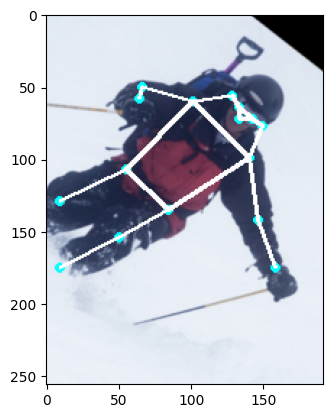

In [72]:
idx = random.randint(0, len(dataset)-1)
# idx = 133743
image, keypoints = dataset[idx]

print(f"Num keypoints: {(keypoints[:,2] > 0).sum()}")
kp = keypoints[:,:2].reshape(1,17,2)
vis = keypoints[:,2].reshape(1,17)
image = draw_keypoints(image, kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
image = to_pil(image)
plt.imshow(image)
plt.show()

index: 68270


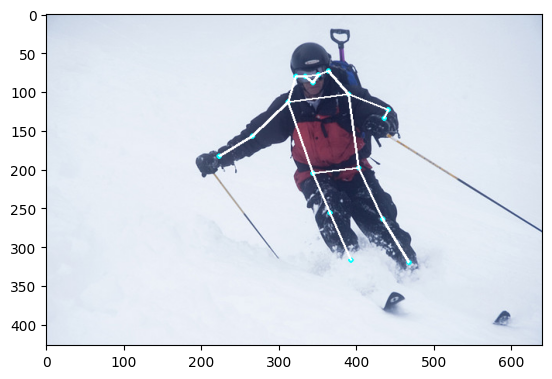

In [73]:
print(f"index: {idx}")
sample = dataset.get_sample(idx)
image_meta = dataset.get_image_meta(sample['image_id'])
image_path = image_meta['file_name']
image = read_image(image_path)
kp = sample['keypoints'][:,:2].reshape(1,17,2)
vis = sample['keypoints'][:,2].reshape(1,17,1)
image = draw_keypoints(image, kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
image = to_pil(image)
plt.imshow(image)
plt.show()

keypoint transform이 제대로 되지 않는 annotation index

## 까다로운 케이스들

(해결됨) 세로로 긴 샘플(특히 사진 왼쪽에 bbox가 붙어 있는 경우)에서는 잘 안 된다. (가운데 부분이 크랍되는 이슈)
- 126423
- 38328
- 77339

(해결됨) 좌우 사이드에 bbox가 붙어 있는 경우, 가운데 부분으로 확대돼서, cropped image만 보고서는 뭔지 가늠하기 어려운 경우가 있다. (위 이슈랑 어찌보면 같은 이슈)
- 111894
- 90045

(해결됨) 에러 발생했던 케이스들
- 133743